# 7장. 그래프로 데이터의 이야기를 보여주기

이 노트북은 `notebooks/ch07_visualization.ipynb` 강의안을 실습하며 과제 답안을 작성한 자료다.

## 제출 정보

이름: 박성주 / GitHub ID: mikeypark / 작성일: 2026-10-24

## 학습 목표

6장에서 집계하고 검증한 결과를 그래프로 표현하고, 그래프에서 직접 읽을 수 있는 사실과 내가 이유를 붙인 해석을 따로 적는 것을 목표로 잡았다. 그래프를 많이 그리는 것보다, 만든 그래프의 수치가 집계표 숫자와 일치하는지 끝에서 교차 검증하는 과정을 중심으로 진행했다.

## 1. 패키지와 경로 설정

In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == 'chapter07' else CURRENT_DIR

PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR = PROJECT_ROOT / 'reports'
REPORT_DIR.mkdir(exist_ok=True)

IMAGE_DIR = (
    CURRENT_DIR / 'images' if CURRENT_DIR.name == 'chapter07'
    else PROJECT_ROOT / 'chapter07' / 'images'
)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('현재 실행 위치:', CURRENT_DIR)
print('프로젝트 루트:', PROJECT_ROOT)
print('전처리 데이터 폴더:', PROCESSED_DIR)
print('이미지 저장 폴더:', IMAGE_DIR)

현재 실행 위치: C:\Users\uncle\Desktop\서울대 응용공학과\수업\2학기\대규모언어모델\git\llm-data-analysis-study\chapter07
프로젝트 루트: C:\Users\uncle\Desktop\서울대 응용공학과\수업\2학기\대규모언어모델\git\llm-data-analysis-study
전처리 데이터 폴더: C:\Users\uncle\Desktop\서울대 응용공학과\수업\2학기\대규모언어모델\git\llm-data-analysis-study\data\processed
이미지 저장 폴더: C:\Users\uncle\Desktop\서울대 응용공학과\수업\2학기\대규모언어모델\git\llm-data-analysis-study\chapter07\images


## 2. 한글 폰트 설정

Windows 환경이라 `Malgun Gothic`을 사용했다. 폰트를 설정하지 않으면 한글 제목과 축 이름이 깨진다.

In [2]:
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

print('matplotlib 한글 폰트 설정 완료')

matplotlib 한글 폰트 설정 완료


## 3. 전처리 데이터 불러오기

파일이 없으면 먼저 터미널에서 `python scripts/preprocess_data.py`를 실행해야 한다.

In [3]:
required_files = [
    PROCESSED_DIR / 'customers_clean.csv',
    PROCESSED_DIR / 'products_clean.csv',
    PROCESSED_DIR / 'orders_clean.csv',
    PROCESSED_DIR / 'order_items_clean.csv',
]

missing_files = [p for p in required_files if not p.exists()]
if missing_files:
    raise FileNotFoundError('전처리 파일이 없습니다: ' + ', '.join(str(p) for p in missing_files))

customers = pd.read_csv(PROCESSED_DIR / 'customers_clean.csv')
products = pd.read_csv(PROCESSED_DIR / 'products_clean.csv')
orders = pd.read_csv(PROCESSED_DIR / 'orders_clean.csv')
order_items = pd.read_csv(PROCESSED_DIR / 'order_items_clean.csv')

orders['order_date'] = pd.to_datetime(orders['order_date'], errors='coerce')
if 'order_month' not in orders.columns:
    orders['order_month'] = orders['order_date'].dt.to_period('M').astype(str)
if 'line_total' not in order_items.columns:
    order_items['line_total'] = order_items['quantity'] * order_items['unit_price']

print('전처리 데이터 불러오기 완료')

전처리 데이터 불러오기 완료


## 4. 시각화 질문 정의

6장 EDA에서 만든 집계 결과를 그대로 활용해서 질문마다 어떤 그래프를 쓸지 이유를 먼저 정했다. 그래프 종류를 고를 때는 질문의 성격(범주 비교 / 시간 흐름 / 분포)을 먼저 보고 골랐다.

In [4]:
viz_questions = pd.DataFrame({
    'question': [
        '카테고리별 completed 매출은 어떻게 다른가?',
        '월별 completed 매출과 주문 수는 어떻게 변하는가?',
        '상품 가격은 어떤 구간에 몰려 있는가?',
    ],
    'graph_type': [
        '세로 막대그래프',
        '선 그래프 (이중 축)',
        '히스토그램',
    ],
    'reason': [
        '범주별 크기 비교이므로 막대그래프. completed 기준인 이유는 6장과 같다 — 취소·환불이 38.67%라 전체 합산 시 매출이 과대 계상됨.',
        '시간 순서가 있는 연속 변화이므로 선 그래프. 주문 수를 막대(이중 축)로 같이 그려서 매출과 건수가 같이 움직이는지 확인했다.',
        '연속형 숫자의 분포이므로 히스토그램. 구간별 상품 수를 보면 저가·중가·고가 비중을 한눈에 볼 수 있다.',
    ],
    'save_as': ['images/graph01.png', 'images/graph02.png', 'images/graph03.png'],
})

viz_questions

,question,graph_type,reason,save_as
0,카테고리별 completed 매출은 어떻게 다른가?,세로 막대그래프,범주별 크기 비교이므로 막대그래프. completed 기준인 이유는 6장과 같다 —...,images/graph01.png
1,월별 completed 매출과 주문 수는 어떻게 변하는가?,선 그래프 (이중 축),시간 순서가 있는 연속 변화이므로 선 그래프. 주문 수를 막대(이중 축)로 같이 그...,images/graph02.png
2,상품 가격은 어떤 구간에 몰려 있는가?,히스토그램,연속형 숫자의 분포이므로 히스토그램. 구간별 상품 수를 보면 저가·중가·고가 비중을...,images/graph03.png


### 왜 이 질문을 선택했는가

카테고리 매출과 월별 매출은 6장 검증을 마친 숫자라서 집계 오류 없이 바로 그래프로 쓸 수 있었다. 상품 가격 분포는 앞의 두 질문이 모두 금액 중심인 것과 달리 상품 자체의 구성을 보여주는 질문이라, 다른 각도를 추가하고 싶어서 골랐다.

## 5. completed 집계 데이터 준비

그래프를 그리기 전에 원본 집계표를 먼저 확인한다. 6장과 동일하게 `order_status == 'completed'`로 필터링하고, 집계 합계가 맞는지 다시 검증했다.

In [5]:
print('orders.order_id 중복 수:', orders['order_id'].duplicated().sum())

order_sales = order_items.merge(
    orders[['order_id', 'customer_id', 'order_date', 'order_month', 'order_status', 'payment_method']],
    on='order_id',
    how='left',
    validate='many_to_one',
    indicator=True,
)

print('병합 전 행 수:', len(order_items))
print('병합 후 행 수:', len(order_sales))
print('_merge 분포:')
print(order_sales['_merge'].value_counts().to_string())
order_sales = order_sales.drop(columns='_merge')

orders.order_id 중복 수: 0
병합 전 행 수: 764
병합 후 행 수: 764
_merge 분포:
_merge
both          764
left_only       0
right_only      0


In [6]:
completed_order_sales = order_sales[order_sales['order_status'] == 'completed'].copy()

print('products.product_id 중복 수:', products['product_id'].duplicated().sum())

completed_sales_items = completed_order_sales.merge(
    products,
    on='product_id',
    how='left',
    validate='many_to_one',
    indicator=True,
)
completed_sales_items = completed_sales_items.drop(columns='_merge')

completed_total = completed_order_sales['line_total'].sum()
print('completed 행 수:', len(completed_order_sales))
print('completed 원본 합계:', f'{completed_total:,.0f}원')

products.product_id 중복 수: 0
completed 행 수: 474
completed 원본 합계: 148,990,000원


In [7]:
# 카테고리별 completed 매출
category_sales = (
    completed_sales_items
    .groupby('category', as_index=False)
    .agg(
        total_quantity=('quantity', 'sum'),
        total_sales=('line_total', 'sum'),
    )
    .sort_values('total_sales', ascending=False)
)
category_sales['sales_ratio'] = (
    category_sales['total_sales'] / category_sales['total_sales'].sum() * 100
).round(2)

category_sales

,category,total_quantity,total_sales,sales_ratio
3,스포츠,295,31743000,21.31
5,전자기기,259,26400000,17.72
2,생활용품,272,23915000,16.05
1,뷰티,223,23383000,15.69
4,식품,133,16573000,11.12
0,도서,149,16389000,11.00
6,패션,111,10587000,7.11


In [8]:
# 월별 completed 매출
monthly_sales = (
    completed_order_sales
    .groupby('order_month', as_index=False)
    .agg(
        total_sales=('line_total', 'sum'),
        order_count=('order_id', 'nunique'),
    )
    .sort_values('order_month')
)

monthly_sales

,order_month,total_sales,order_count
0,2025-07,5869000,8
1,2025-08,15621000,18
2,2025-09,10190000,13
3,2025-10,25766000,26
4,2025-11,8812000,12
5,2025-12,11501000,14
6,2026-01,17423000,22
7,2026-02,9749000,17
8,2026-03,13429000,14
9,2026-04,17553000,23


In [9]:
# 집계 합계 재검증
cat_sum = category_sales['total_sales'].sum()
mon_sum = monthly_sales['total_sales'].sum()

print('completed 원본 합계:', f'{completed_total:,.0f}')
print('카테고리별 합계:', f'{cat_sum:,.0f}', '일치:', cat_sum == completed_total)
print('월별 합계    :', f'{mon_sum:,.0f}', '일치:', mon_sum == completed_total)

completed 원본 합계: 148,990,000
카테고리별 합계: 148,990,000 일치: True
월별 합계    : 148,990,000 일치: True


### 결과 관찰

6장에서 검증했던 숫자(completed 원본 합계 148,990,000원)가 그대로 나왔고 카테고리별·월별 합계도 일치했다. 데이터를 다시 불러와서 집계해도 같은 숫자가 나온다는 게 확인됐으니 이 집계표를 그래프 원본으로 그대로 쓰기로 했다.

## 6. 그래프 1 — 카테고리별 completed 매출 막대그래프

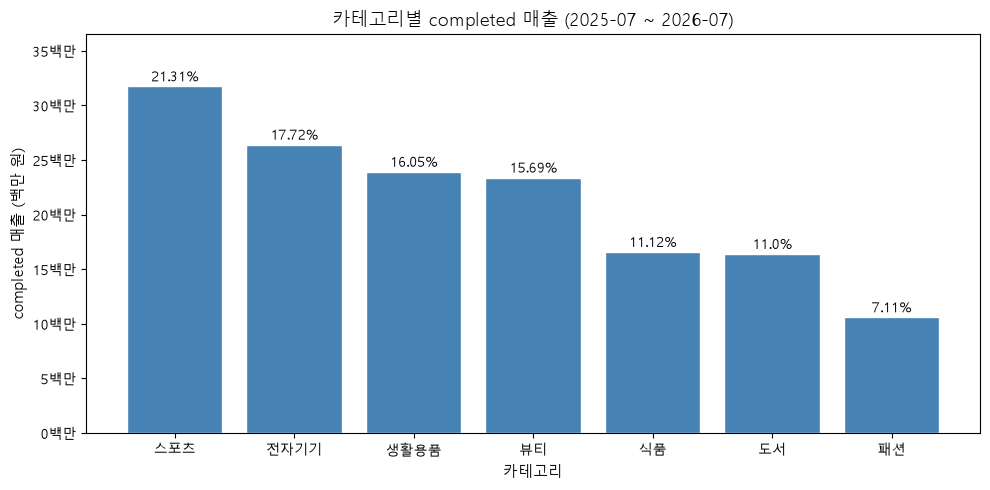

graph01.png 저장 완료


In [10]:
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    category_sales['category'],
    category_sales['total_sales'],
    color='steelblue',
    edgecolor='white',
)

for bar, ratio in zip(bars, category_sales['sales_ratio']):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 200_000,
        f'{ratio}%',
        ha='center', va='bottom', fontsize=10,
    )

ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1_000_000:.0f}백만'))
ax.set_title('카테고리별 completed 매출 (2025-07 ~ 2026-07)', fontsize=13)
ax.set_xlabel('카테고리', fontsize=11)
ax.set_ylabel('completed 매출 (백만 원)', fontsize=11)
ax.set_ylim(0, category_sales['total_sales'].max() * 1.15)

plt.tight_layout()
plt.savefig(IMAGE_DIR / 'graph01.png', dpi=150, bbox_inches='tight')
plt.show()
print('graph01.png 저장 완료')

### 원본 집계값

6장 category_sales 검증 결과 그대로 사용했다. 스포츠 31,743,000원(21.31%) ~ 패션 10,587,000원(7.11%). 카테고리별 합계 = completed 원본 합계 148,990,000원.

### 결과 관찰

스포츠(21.31%)가 가장 높고 패션(7.11%)이 가장 낮다. 1위 스포츠와 7위 패션의 차이가 약 3배(31.7백만 대 10.6백만)다. 상위 3개(스포츠·전자기기·생활용품)를 더하면 전체의 55.1%가 된다.

### 나의 해석과 판단

스포츠가 1위인 건 판매 수량(295개)이 가장 많기 때문이다. 패션은 평균 단가(115,909원)가 7개 중 3위인데 매출이 꼴찌인 이유는 판매 수량(111개, 최저)이 적어서다. 6장에서 이미 확인한 내용인데 그래프로 보니 패션 막대가 얼마나 작은지 수치보다 훨씬 직관적으로 들어왔다.

### 업무·분석적 의미

매출 기여도 순위를 시각화하면 판촉·재고 배분 우선순위를 정할 때 출발점이 생긴다. 단 이 순위는 completed 기준이어서, 카테고리별 취소·환불 비율이 다를 경우 순위가 달라질 수 있다(-> 12번 다음 분석 우선순위).

### 한계와 추가 확인 사항

- 막대 높이가 매출이지 수익이 아니다. 마진이 다른 카테고리를 매출만으로 비교하면 기여도가 달리 보일 수 있다.
- 관측 기간(13개월)에 특정 카테고리 프로모션이 있었다면 이 순위는 평상시와 다를 수 있다.

## 7. 그래프 2 — 월별 completed 매출 선 그래프

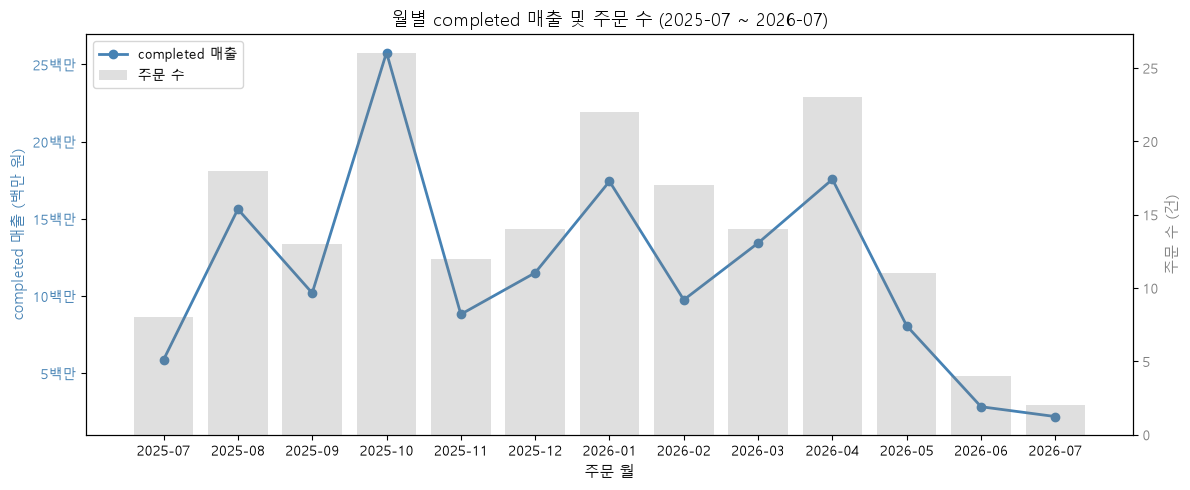

graph02.png 저장 완료


In [11]:
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(
    monthly_sales['order_month'],
    monthly_sales['total_sales'],
    marker='o', color='steelblue', linewidth=2, label='completed 매출',
)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1_000_000:.0f}백만'))
ax1.set_ylabel('completed 매출 (백만 원)', fontsize=11, color='steelblue')
ax1.tick_params(axis='y', labelcolor='steelblue')

ax2 = ax1.twinx()
ax2.bar(
    monthly_sales['order_month'],
    monthly_sales['order_count'],
    alpha=0.25, color='gray', label='주문 수',
)
ax2.set_ylabel('주문 수 (건)', fontsize=11, color='gray')
ax2.tick_params(axis='y', labelcolor='gray')

ax1.set_title('월별 completed 매출 및 주문 수 (2025-07 ~ 2026-07)', fontsize=13)
ax1.set_xlabel('주문 월', fontsize=11)
plt.xticks(rotation=45)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
plt.savefig(IMAGE_DIR / 'graph02.png', dpi=150, bbox_inches='tight')
plt.show()
print('graph02.png 저장 완료')

### 원본 집계값

월별 합계 = 148,990,000원. 2025-07(5,869,000원·8건) ~ 2026-07(2,188,000원·2건). 피크는 2025-10(25,766,000원·26건).

### 결과 관찰

2025-10에 매출과 주문 수가 동시에 가장 높았고 그 후 2025-11에 급감, 2026-01과 2026-04에 다시 올라오는 흐름이 보인다. 2026-06·07은 주문이 4건, 2건밖에 없어서 매출도 다른 달에 비해 훨씬 낮다.

### 나의 해석과 판단

2025-10 피크는 매출과 주문 수가 함께 올라갔으니 건당 단가가 아니라 주문 건수 자체가 많아진 것이다. 6장에서 같은 관찰을 했는데 그래프로 보니 폭이 얼마나 크게 튀는지 시각적으로 더 잘 보였다. 2026-06~07 급감은 데이터 수집이 2026-07-08에 끝났기 때문에 해당 월이 완성되지 않은 데이터일 가능성이 높다. 이걸 '최근 매출 하락'으로 단정하면 잘못된 결론이 나온다.

이중 축 구조는 두 변수의 스케일이 다를 때 쓰기 좋지만, 스케일 설정에 따라 관계를 과장하거나 축소할 수 있다는 위험이 있어서 여기서는 방향이 같이 움직이는지 확인하는 용도로만 썼다.

### 업무·분석적 의미

2025-10처럼 특정 월에 주문이 집중되는 패턴이 있다면 재고·인력을 사전에 준비하는 데 참고할 수 있다. 단 1년치 데이터만 있어서 이게 반복되는 계절성인지 일회성인지는 지금 확인할 수 없다.

### 한계와 추가 확인 사항

- 2026-06~07은 월이 완성되지 않았을 가능성이 높아서 다른 월과 직접 비교하는 건 부적절하다.
- 월별 매출 변화의 원인(프로모션, 계절성, 신규 고객 유입 등)은 지금 데이터만으로 알 수 없다.

## 8. 그래프 3 — 상품 가격 분포 히스토그램

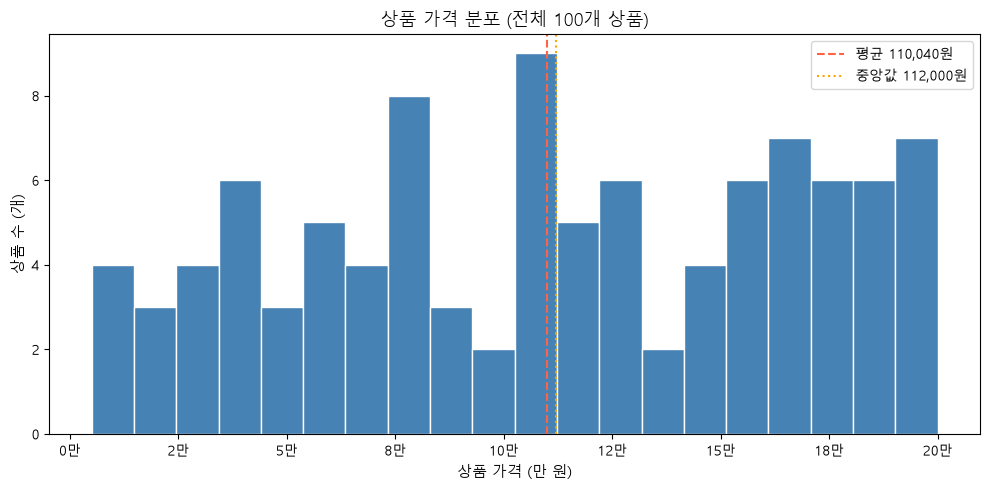

graph03.png 저장 완료


In [12]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(products['price'], bins=20, color='steelblue', edgecolor='white')

ax.axvline(
    products['price'].mean(), color='tomato', linestyle='--', linewidth=1.5,
    label=f'평균 {products["price"].mean():,.0f}원',
)
ax.axvline(
    products['price'].median(), color='orange', linestyle=':', linewidth=1.5,
    label=f'중앙값 {products["price"].median():,.0f}원',
)

ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/10_000:.0f}만'))
ax.set_title('상품 가격 분포 (전체 100개 상품)', fontsize=13)
ax.set_xlabel('상품 가격 (만 원)', fontsize=11)
ax.set_ylabel('상품 수 (개)', fontsize=11)
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig(IMAGE_DIR / 'graph03.png', dpi=150, bbox_inches='tight')
plt.show()
print('graph03.png 저장 완료')

### 원본 집계값

전체 100개 상품. 최솟값 5,000원·중앙값 112,000원·평균 110,040원·최댓값 200,000원.

### 결과 관찰

5,000원부터 200,000원까지 넓게 분포해 있고 10~15만 원대 구간에 상품이 가장 많이 몰려 있다. 평균(110,040원)과 중앙값(112,000원)이 거의 같아서 분포가 한쪽으로 크게 치우치지 않았다. 5,000원 같은 저가 상품이 있긴 하지만 주류는 중고가 구간이다.

### 나의 해석과 판단

평균과 중앙값이 비슷하다는 건 극단적으로 비싸거나 싼 상품이 전체 분포를 끌어당기지 않는다는 뜻이다. 상품 구성이 중고가 중심인 것으로 보이는데, 이게 의도한 기획인지 데이터 특성인지는 알 수 없다. 6장에서 카테고리별 평균 단가를 봤을 때 식품이 가장 비싸고 생활용품이 가장 쌌는데, 이 히스토그램은 그 차이가 전체 분포 수준에서는 크게 드러나지 않는다는 걸 보여준다.

### 업무·분석적 의미

상품 가격대 분포를 알면 가격 전략(저가 상품 확충 vs. 고가 상품 비중 유지)을 논의할 때 출발점이 생긴다. 단 이 히스토그램은 전체 100개 상품의 가격 분포이고, 실제 판매된 상품의 가격 분포와 다를 수 있다.

### 한계와 추가 확인 사항

- bins=20으로 설정했는데 구간 크기를 다르게 하면 분포 모양이 달리 보일 수 있다.
- 많이 팔린 상품과 안 팔린 상품의 가격 분포가 다른지는 따로 확인해야 한다(-> 과제 5 산점도).

## 9. 그래프 수치 교차 검증

대표 그래프 3개의 주요 수치가 실제 집계표 값과 일치하는지 확인했다.

In [13]:
# graph01: 스포츠 매출 1위 수치
sports_val = category_sales.loc[category_sales['category'] == '스포츠', 'total_sales'].iloc[0]
assert sports_val == 31_743_000, f'스포츠 매출 불일치: {sports_val}'

# graph01: 패션 매출 최하위 수치
fashion_val = category_sales.loc[category_sales['category'] == '패션', 'total_sales'].iloc[0]
assert fashion_val == 10_587_000, f'패션 매출 불일치: {fashion_val}'

# graph02: 2025-10 매출 및 주문 수
oct_row = monthly_sales[monthly_sales['order_month'] == '2025-10'].iloc[0]
assert oct_row['total_sales'] == 25_766_000, f'2025-10 매출 불일치: {oct_row["total_sales"]}'
assert oct_row['order_count'] == 26, f'2025-10 주문 수 불일치: {oct_row["order_count"]}'

# graph03: 상품 수 및 가격 평균
assert len(products) == 100, f'상품 수 불일치: {len(products)}'
assert abs(products['price'].mean() - 110_040.0) < 1, f'가격 평균 불일치: {products["price"].mean()}'

print('그래프 수치 교차 검증 모두 통과')

그래프 수치 교차 검증 모두 통과


### 결과 관찰

assert 6개 모두 통과했다. 그래프를 그릴 때 집계표에서 직접 가져온 숫자를 썼기 때문에 당연한 결과이긴 한데, 막대 높이를 눈으로 보고 '스포츠가 제일 높아 보인다'라고만 적는 게 아니라 실제 값을 코드로 검증하고 나니 그래프가 정확하다는 걸 확인하는 과정이 있었다는 게 중요하다고 생각했다.

## 10. 그래프 정확성 점검

- [x] 그래프 값과 집계표 값 일치 (9번 셀에서 assert 통과)
- [x] 축 이름 확인 (카테고리·매출, 주문 월·매출·주문 수, 가격·상품 수)
- [x] 단위 확인 (백만 원, 만 원 표기)
- [x] 범례 확인 (graph02에서 매출 선·주문 수 막대 범례 추가)
- [x] 날짜 정렬 확인 (monthly_sales가 order_month 기준 오름차순)
- [x] 과장될 수 있는 축 범위 확인 (y축 0 시작, ylim 최댓값 1.15배)
- [x] 제목이 분석 범위를 정확히 표현 (completed, 기간 명시)

### 내가 발견한 시각화 위험 또는 개선점

graph02의 이중 축 구조는 매출과 주문 수가 같이 움직이는지 확인하는 데 편리하지만, 오른쪽 축(주문 수)의 스케일을 조정하면 같은 데이터로도 관계가 강하게 보이게 할 수 있다. 지금은 기본값으로 뒀는데 보고서에 넣을 때는 이 점을 독자에게 명시해야 할 것 같다. graph01의 y축은 0에서 시작하도록 했는데, 중간을 잘라서 시작하면 카테고리 간 차이가 실제보다 커 보일 수 있어서 그렇게 하지 않았다.

## 11. 실습 과제

### 과제 1. 카테고리별 판매 수량 막대그래프를 추가로 그려 보세요.

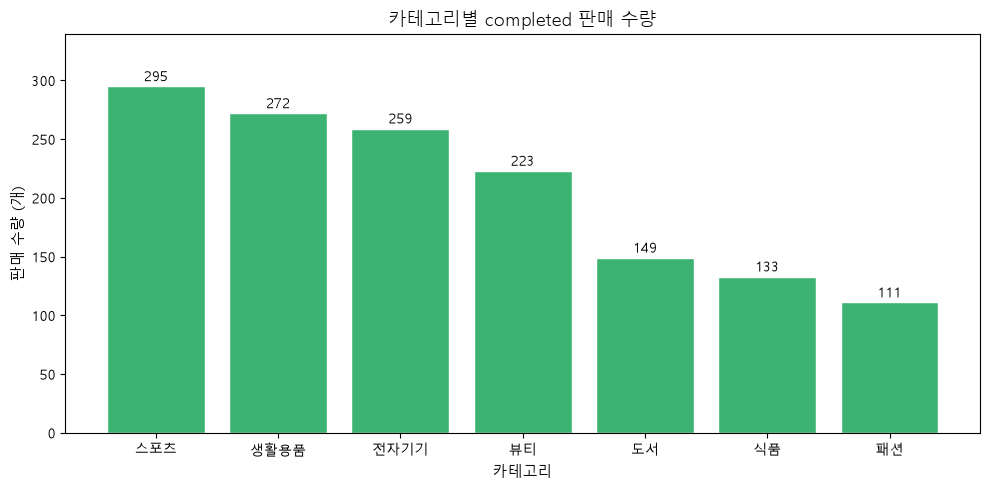

hw01 저장 완료


In [14]:
# 과제 1. 카테고리별 completed 판매 수량
cat_qty = category_sales.sort_values('total_quantity', ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(cat_qty['category'], cat_qty['total_quantity'], color='mediumseagreen', edgecolor='white')

for bar, val in zip(ax.patches, cat_qty['total_quantity']):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        str(val),
        ha='center', va='bottom', fontsize=10,
    )

ax.set_title('카테고리별 completed 판매 수량', fontsize=13)
ax.set_xlabel('카테고리', fontsize=11)
ax.set_ylabel('판매 수량 (개)', fontsize=11)
ax.set_ylim(0, cat_qty['total_quantity'].max() * 1.15)
plt.tight_layout()
plt.savefig(IMAGE_DIR / 'hw01_category_quantity.png', dpi=150, bbox_inches='tight')
plt.show()
print('hw01 저장 완료')

### 결과 관찰

판매 수량 1위는 스포츠(295개), 최하위는 패션(111개)으로 매출 순위(graph01)와 순서가 거의 같다. 스포츠는 매출도 높고 수량도 가장 많아서 단가와 수량 모두에서 우위에 있다는 걸 다시 확인했다. 식품은 매출 순위(5위)보다 수량 순위(6위)가 낮은데, 이는 6장에서 본 것처럼 식품의 평균 단가(137,143원)가 가장 비싸서 적은 수량으로도 매출이 높게 나온 것이다.

### 과제 2. 결제수단별 주문 수 막대그래프를 그려 보세요.

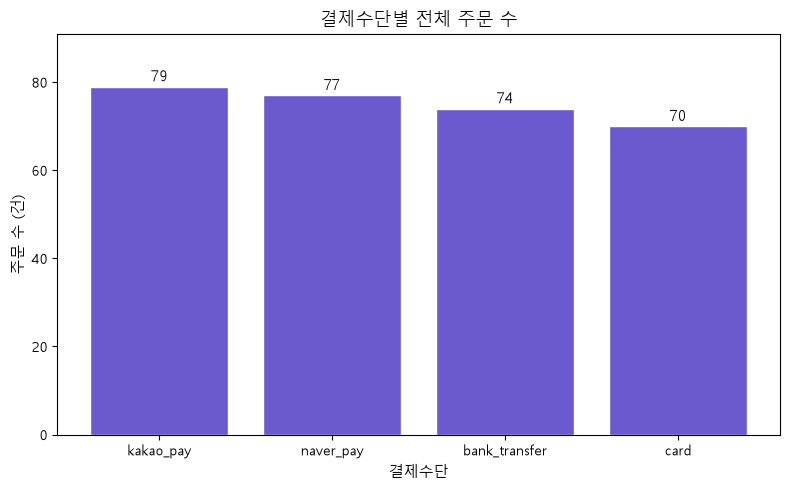

hw02 저장 완료


In [15]:
# 과제 2. 결제수단별 전체 주문 수
payment_count = (
    orders['payment_method'].value_counts(dropna=False)
    .reset_index()
)
payment_count.columns = ['payment_method', 'order_count']
payment_count = payment_count.sort_values('order_count', ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(payment_count['payment_method'], payment_count['order_count'],
              color='slateblue', edgecolor='white')

for bar, val in zip(bars, payment_count['order_count']):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        str(val),
        ha='center', va='bottom', fontsize=11,
    )

ax.set_title('결제수단별 전체 주문 수', fontsize=13)
ax.set_xlabel('결제수단', fontsize=11)
ax.set_ylabel('주문 수 (건)', fontsize=11)
ax.set_ylim(0, payment_count['order_count'].max() * 1.15)
plt.tight_layout()
plt.savefig(IMAGE_DIR / 'hw02_payment_count.png', dpi=150, bbox_inches='tight')
plt.show()
print('hw02 저장 완료')

### 결과 관찰

kakao_pay(79건), naver_pay(77건), bank_transfer(74건), card(70건) 순으로, 네 가지 결제수단의 주문 수 차이가 9건(최대 79 - 최소 70)으로 매우 적다. 6장에서 비율로 봤을 때 23~26% 사이였는데 그래프로 보니 막대 높이 차이가 거의 없어서 '사실상 고르다'는 게 더 잘 보였다.

### 과제 3. 고객 나이 분포 히스토그램을 그려 보세요.

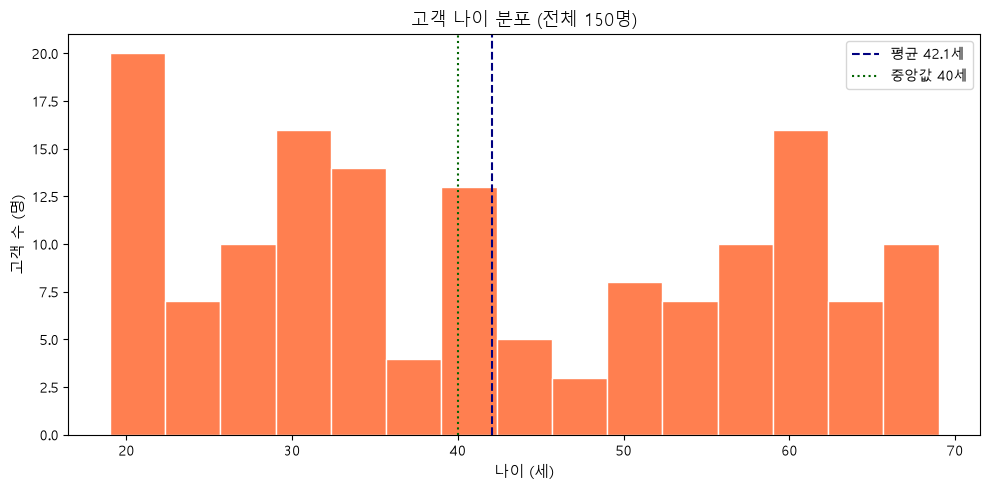

hw03 저장 완료


In [16]:
# 과제 3. 고객 나이 분포
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(customers['age'], bins=15, color='coral', edgecolor='white')
ax.axvline(
    customers['age'].mean(), color='navy', linestyle='--', linewidth=1.5,
    label=f'평균 {customers["age"].mean():.1f}세',
)
ax.axvline(
    customers['age'].median(), color='darkgreen', linestyle=':', linewidth=1.5,
    label=f'중앙값 {customers["age"].median():.0f}세',
)
ax.set_title('고객 나이 분포 (전체 150명)', fontsize=13)
ax.set_xlabel('나이 (세)', fontsize=11)
ax.set_ylabel('고객 수 (명)', fontsize=11)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(IMAGE_DIR / 'hw03_customer_age.png', dpi=150, bbox_inches='tight')
plt.show()
print('hw03 저장 완료')

### 결과 관찰

고객 나이는 19세부터 69세까지 분포하고 평균 42.1세, 중앙값 40세로 두 값이 비슷하다. graph03의 상품 가격 분포와 비슷하게 평균과 중앙값이 가까운 편이고, 30~50대 구간이 넓게 퍼져 있는 것으로 보인다. 20대 이하나 60대 이상이 상대적으로 적다는 것도 확인됐다.

### 과제 4. 월별 주문 수 선 그래프를 그려 보세요.

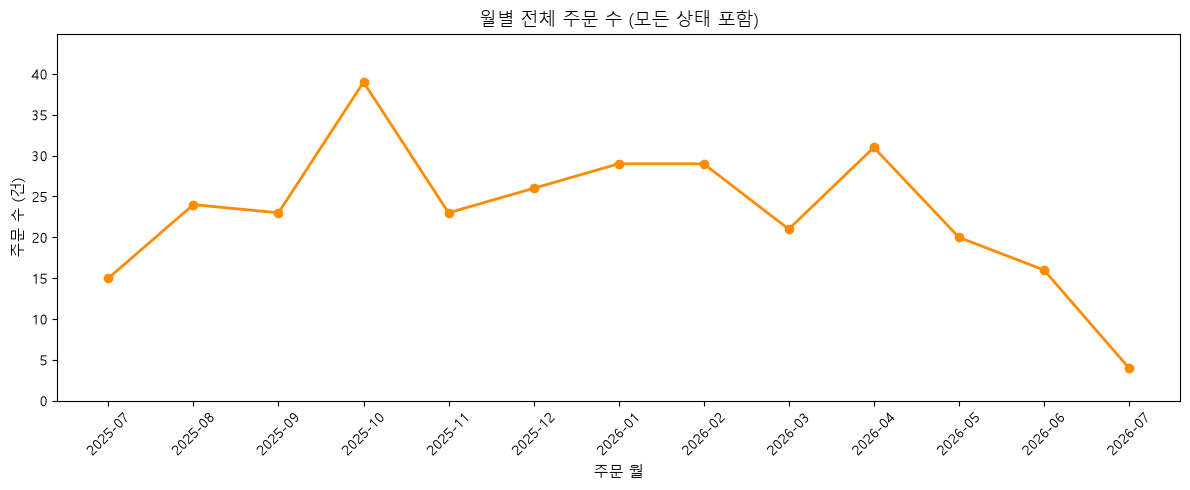

hw04 저장 완료


In [17]:
# 과제 4. 월별 전체 주문 수 (모든 상태 포함)
monthly_order_count = (
    orders
    .groupby('order_month', as_index=False)
    .agg(order_count=('order_id', 'count'))
    .sort_values('order_month')
)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    monthly_order_count['order_month'],
    monthly_order_count['order_count'],
    marker='o', color='darkorange', linewidth=2,
)
ax.set_title('월별 전체 주문 수 (모든 상태 포함)', fontsize=13)
ax.set_xlabel('주문 월', fontsize=11)
ax.set_ylabel('주문 수 (건)', fontsize=11)
ax.set_ylim(0, monthly_order_count['order_count'].max() * 1.15)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(IMAGE_DIR / 'hw04_monthly_order_count.png', dpi=150, bbox_inches='tight')
plt.show()
print('hw04 저장 완료')

### 결과 관찰

전체 주문 수(모든 상태 포함) 흐름이 completed 매출(graph02)과 비슷하게 2025-10에 가장 높고 2026-06~07에 급감하는 패턴을 보인다. 이 두 그래프를 같이 보면 월별 completed 매출 변화가 주로 주문 건수 변화에서 온다는 걸 간접적으로 확인할 수 있다.

### 과제 5. 고객별 주문 횟수와 총 구매 금액의 관계를 산점도로 그려 보세요.

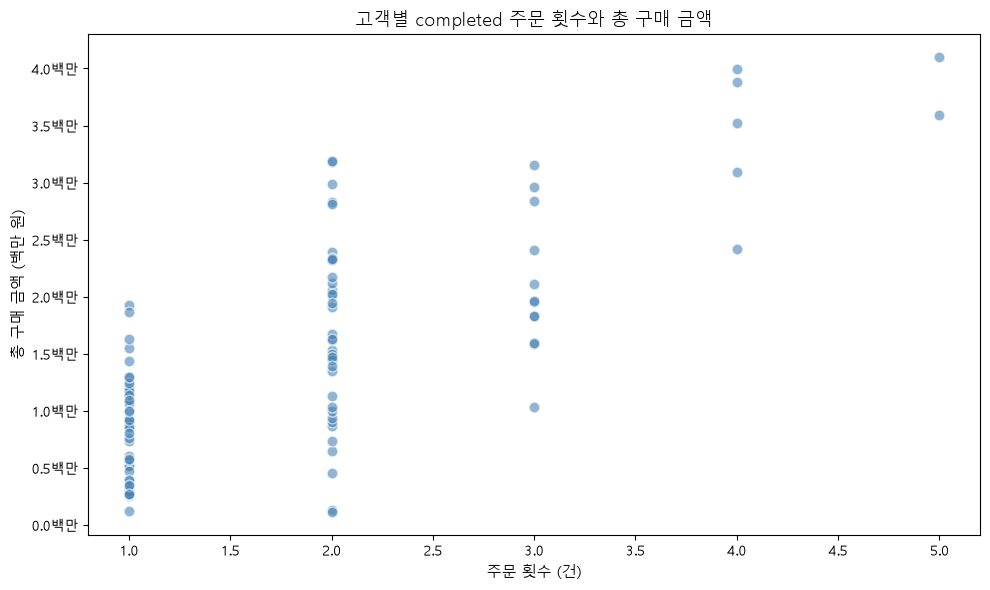

hw05 저장 완료


In [18]:
# 과제 5. 고객별 주문 횟수와 총 구매 금액 산점도
customer_summary = (
    completed_order_sales
    .groupby('customer_id', as_index=False)
    .agg(
        order_count=('order_id', 'nunique'),
        total_sales=('line_total', 'sum'),
    )
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(
    customer_summary['order_count'],
    customer_summary['total_sales'],
    alpha=0.6, color='steelblue', edgecolors='white', s=60,
)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1_000_000:.1f}백만'))
ax.set_title('고객별 completed 주문 횟수와 총 구매 금액', fontsize=13)
ax.set_xlabel('주문 횟수 (건)', fontsize=11)
ax.set_ylabel('총 구매 금액 (백만 원)', fontsize=11)
plt.tight_layout()
plt.savefig(IMAGE_DIR / 'hw05_order_count_vs_sales.png', dpi=150, bbox_inches='tight')
plt.show()
print('hw05 저장 완료')

### 결과 관찰

주문 횟수가 많을수록 총 구매 금액이 높아지는 대체적인 경향이 있지만, 왼쪽 위(주문 2건인데 총 구매 금액이 높은)에 흩어진 점들이 있다. 6장에서 Customer 20(2건, 건당 1,595,500원)처럼 단발 고액 구매 고객을 수치로 확인했는데, 산점도에서 그 위치가 '왼쪽 위'에 해당한다는 걸 시각적으로 확인했다. 주문 횟수와 총 구매 금액의 상관이 완벽하지 않다는 것도 산점도에서 더 잘 보인다.

### 과제 6. 위 그래프 중 2개를 `chapter07/images/` 폴더에 저장하세요.

In [19]:
# 과제 6. 저장 확인 — 각 셀에서 IMAGE_DIR에 이미 저장했으니 목록만 확인
saved = sorted(IMAGE_DIR.glob('*.png'))
print(f'chapter07/images/ 저장 파일 ({len(saved)}개):')
for p in saved:
    print(' ', p.name)

chapter07/images/ 저장 파일 (8개):
  graph01.png
  graph02.png
  graph03.png
  hw01_category_quantity.png
  hw02_payment_count.png
  hw03_customer_age.png
  hw04_monthly_order_count.png
  hw05_order_count_vs_sales.png


### 결과 관찰

각 셀에서 `IMAGE_DIR / '파일명.png'`으로 저장했기 때문에 모든 그래프가 `chapter07/images/`에 들어가 있다. 대표 그래프 3개(graph01~03)와 과제용 5개(hw01~05)가 모두 저장됐다.

## 12. LLM으로 그래프 해석 점검하기

### 사용 목적

그래프 3개의 해석 문장을 쓰고 나서 '관찰'인지 '원인 추정'인지 경계가 불분명한 문장이 있었다. LLM을 써서 내가 쓴 문장이 관찰인지 추정인지를 점검받았다.

### Safe Context로 제공한 요약

```text
카테고리별 completed 매출: 스포츠 21.31%(최대), 패션 7.11%(최소)
월별 completed 매출: 2025-10 피크(25,766,000원·26건), 2026-06~07 급감(4건·2건)
데이터 수집 종료일: 2026-07-08
상품 가격 분포: 5,000~200,000원, 평균≒중앙값≒11만 원
```

### 사용한 Prompt

```text
위 요약을 보고 아래 해석 문장 3개에서 '관찰(데이터에서 직접 읽은 사실)'과
'원인 추정(데이터에 없는 이유를 붙인 것)'을 구분해줘.

문장 1: "2025-10 매출이 높은 건 그 달에 할인 행사가 있었기 때문이다."
문장 2: "2026-06~07 매출이 낮은 건 데이터 수집이 2026-07-08에 끝나서 해당 월이
         완성되지 않았을 가능성이 있다."
문장 3: "패션 매출이 낮은 건 단가가 너무 높아서 고객이 구매를 꺼리기 때문이다."
```

### LLM 답변 요약

- 문장 1: 원인 추정. '할인 행사'는 데이터에 없는 외부 요인이다.
- 문장 2: 조건부 원인 추정이지만 적절히 유보됨. '가능성이 있다'라는 표현이 있어서 단정은 아니다. 데이터 종료일 정보를 근거로 한 추론이라 허용 가능하다.
- 문장 3: 잘못된 원인 추정. 패션 단가(115,909원)는 중간 수준인데, 매출이 낮은 이유는 단가가 아니라 판매 수량(111개, 최소)이 적어서다. '단가가 높아서 고객이 꺼린다'는 데이터에서 확인되지 않은 인과 방향이다.

### 나의 해석과 판단

문장 3 피드백이 가장 도움이 됐다. 처음 해석 초안에서 비슷한 표현을 썼다가 지웠는데, LLM이 같은 이유를 들어 틀렸다고 짚어줬다. 패션 단가가 낮아서 매출이 낮은 게 아니라 수량이 적어서 낮다는 방향이 맞다고 다시 확인했다. 문장 2처럼 '가능성이 있다'는 유보 표현을 쓰면 그 줄 안에서 관찰과 추정을 어느 정도 구분할 수 있다는 것도 배웠다. 단 '가능성이 있다'는 표현도 반복되면 흐릿해지기 때문에, 관찰 셀과 해석 셀을 따로 두는 구조가 더 명확하다고 생각한다.

### 실제 사용 여부: 수정 후 사용

LLM 답변을 그대로 쓰지 않고, 문장 3의 방향이 틀렸다는 점을 받아들여서 해당 섹션의 '나의 해석과 판단'을 직접 고쳐 썼다.

## 13. Chapter 07 최종 판단

### 가장 중요한 그래프 1개와 이유

graph02(월별 completed 매출·주문 수 선 그래프)가 가장 중요하다고 생각한다. graph01은 특정 시점의 단면을 보여주지만, graph02는 13개월 동안 매출이 어떻게 움직였는지를 보여줘서 패턴을 발견하기에 더 유용했다. 특히 2026-06~07 급감이 '데이터 기간이 끝나서'일 수 있다는 판단이 이 그래프를 보고 나서야 가능했고, 이걸 '최근 하락 추세'로 잘못 해석하지 않게 막아줬다.

### 그래프가 보여 준 사실

- 카테고리별 매출: 스포츠가 21.31%로 가장 높고 패션이 7.11%로 가장 낮다. 1위와 7위 차이가 약 3배다.
- 월별 매출: 2025-10에 피크(25,766,000원·26건), 이후 등락 반복. 2026-06~07은 주문 수 자체가 4건·2건이다.
- 상품 가격: 10~15만 원대에 가장 많이 분포. 평균(110,040원)과 중앙값(112,000원)이 거의 같다.

### 그래프만으로 말할 수 없는 것

- 2025-10 피크의 원인(프로모션, 계절성, 신규 고객 유입 등)
- 패션 판매 수량이 왜 가장 적은지(재고·노출·선호도 중 어떤 게 주요 요인인지)
- 상품 가격대 구성이 의도한 기획의 결과인지, 아니면 데이터 특성인지

### 다음 분석에서 확인할 질문

1. 카테고리별 취소·환불 비율을 따로 보면 completed 매출 순위가 달라질 수 있는지 확인하고 싶다.
2. 2025-10 주문 증가가 기존 고객의 재구매인지 신규 고객 유입인지 `signup_date`와 `order_date`를 비교해서 확인해보고 싶다.
3. 과제 5에서 본 '고액 단발 구매 고객'이 이후에 다시 구매했는지 추적하고 싶은데, 지금은 데이터 기간이 짧아서 당장은 어렵다.

## 최종 체크

- [x] 그래프와 수치를 교차 검증했습니다. (9번 셀 assert 통과)
- [x] 관찰과 해석을 구분했습니다.
- [x] 업무적 의미와 한계를 작성했습니다.
- [x] 최종 Notebook URL을 제출합니다.